# Serie de tiempo de la página

**Takens → homología persistente → Wasserstein.** La configuración de referencia usa `log1p`, siete coordenadas con retardo de un día y 28 vectores por nube. Cada nube abarca 34 días. (H_0) describe componentes y (H_1) describe ciclos en la nube.

In [1]:
import csv
from pathlib import Path
from html import escape

raiz = Path.cwd()
if not (raiz / "datos").is_dir() and (raiz.parent / "datos").is_dir():
    raiz = raiz.parent
if not (raiz / "datos").is_dir():
    raise FileNotFoundError("Ejecuta el notebook desde la raíz del proyecto.")

def svg(contenido, ancho=850, alto=250):
    return (f'<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 {ancho} {alto}" '
            f'width="{ancho}" height="{alto}" font-family="system-ui" font-size="13" fill="#18324a">'
            f'<rect width="100%" height="100%" fill="white"/>{contenido}</svg>')

def etiqueta(x, y, texto):
    return f'<text x="{x}" y="{y}">{escape(str(texto))}</text>'

def mostrar(grafico):
    try:
        from IPython.display import SVG, display
    except ImportError:
        return
    display(SVG(grafico))

import json
from math import log1p

def leer(ruta, encoding="utf-8"):
    with (raiz / ruta).open(encoding=encoding, newline="") as archivo:
        return list(csv.DictReader(archivo))

pagina = leer("datos/transformados/series_diarias_pagina.csv", "utf-8-sig")
distancias = leer("enfoque_topologico/distancias.csv")
episodio = json.loads((raiz / "enfoque_topologico/episodio_junio.json").read_text())
print(f"{len(pagina)} días de visualizaciones y {len(distancias)} ventanas de persistencia")


315 días de visualizaciones y 1974 ventanas de persistencia


## Visualizaciones y cambio topológico

Cada distancia corresponde al cierre de la ventana más reciente. Cambia `configuracion` y ejecuta la celda para comparar tamaño de ventana, dimensión o escala. Cada panel tiene su propia escala vertical.

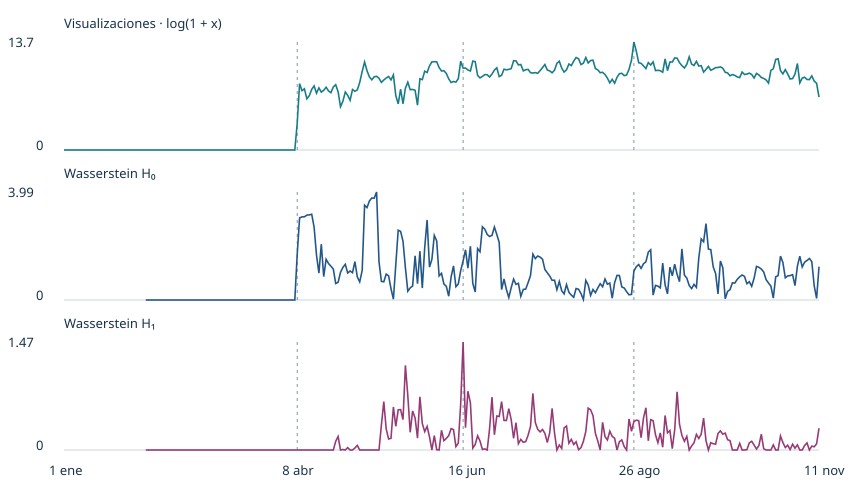

In [2]:

configuracion = ("log1p", 7, 28)
seleccion = {r["fecha"]: r for r in distancias
             if (r["escala"], int(r["dimension"]), int(r["puntos"])) == configuracion}
if not seleccion:
    raise ValueError("La configuración no está en distancias.csv")

fechas = [r["fecha"] for r in pagina]
paneles = [
    ("Visualizaciones · log(1 + x)", "#187c87", [log1p(int(r["pagina_visualizaciones"])) for r in pagina]),
    ("Wasserstein H₀", "#235789", [seleccion.get(d, {}).get("wasserstein_h0") for d in fechas]),
    ("Wasserstein H₁", "#963a75", [seleccion.get(d, {}).get("wasserstein_h1") for d in fechas]),
]
contenido = ""
for panel, (titulo, color, valores) in enumerate(paneles):
    base_y = 150 + 150 * panel
    maximo = max(float(v) for v in valores if v not in (None, ""))
    escala = maximo or 1
    puntos = [(64+755*i/(len(fechas)-1), base_y-108*float(v)/escala)
              for i,v in enumerate(valores) if v not in (None, "")]
    contenido += etiqueta(64, base_y-122, titulo)
    contenido += etiqueta(8, base_y-103, f"{maximo:.3g}") + etiqueta(36, base_y, "0")
    contenido += f'<path d="M64 {base_y} H819" stroke="#ccd5df"/>'
    for fecha in ("2026-04-08", "2026-06-16", "2026-08-26"):
        x = 64 + 755 * fechas.index(fecha) / (len(fechas)-1)
        contenido += f'<path d="M{x} {base_y-108} V{base_y}" stroke="#8194a8" stroke-dasharray="3 4"/>'
    coordenadas = " ".join(f"{x:.1f},{y:.1f}" for x,y in puntos)
    contenido += f'<polyline points="{coordenadas}" fill="none" stroke="{color}" stroke-width="1.6"/>'
for fecha, texto in (("2026-01-01","1 ene"),("2026-04-08","8 abr"),("2026-06-16","16 jun"),
                     ("2026-08-26","26 ago"),("2026-11-11","11 nov")):
    contenido += etiqueta(64 + 755 * fechas.index(fecha)/(len(fechas)-1)-15, 475, texto)
grafico = svg(contenido, alto=495)
mostrar(grafico)


## Del 15 al 17 de junio

Los tres diagramas usan escalas iguales. Cada punto es un intervalo de persistencia de (H_1). Su distancia a la diagonal refleja cuánto duró el ciclo en la filtración. Los puntos de paneles distintos representan los intervalos de esas ventanas.

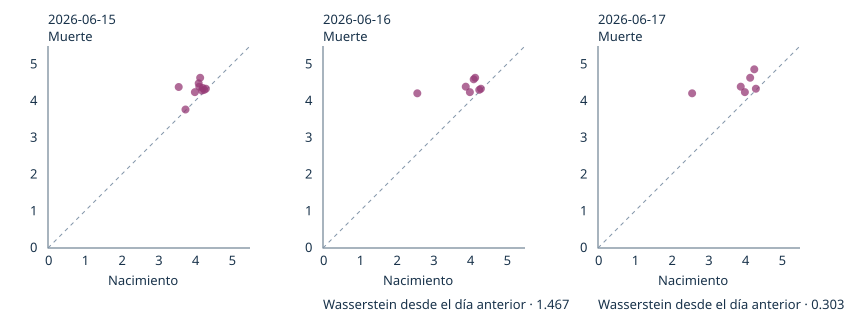

In [3]:

escenario = "observada"  # También disponible: "pico_sustituido".
registros = episodio[escenario]
limite = 5.5
contenido = ""
for i, r in enumerate(registros):
    izquierda = 48 + 275*i
    def x(valor):
        return izquierda + 202*valor/limite
    def y(valor):
        return 248 - 202*valor/limite

    contenido += etiqueta(izquierda, 24, r["fecha"])
    contenido += f'<path d="M{x(0)} {y(limite)} V{y(0)} H{x(limite)}" fill="none" stroke="#52697d"/>'
    contenido += f'<path d="M{x(0)} {y(0)} L{x(limite)} {y(limite)}" stroke="#8194a8" stroke-dasharray="4 4"/>'
    for marca in range(0, 6):
        contenido += etiqueta(x(marca)-3, 265, marca) + etiqueta(izquierda-18, y(marca)+4, marca)
    contenido += etiqueta(izquierda+60, 285, "Nacimiento")
    contenido += etiqueta(izquierda, 41, "Muerte")
    for nacimiento, muerte in r["diagrama_h1"]:
        contenido += f'<circle cx="{x(nacimiento)}" cy="{y(muerte)}" r="4" fill="#963a75" fill-opacity="0.75"/>'
    distancia = r["wasserstein_h1"]
    if distancia is not None:
        contenido += etiqueta(izquierda, 309, f"Wasserstein desde el día anterior · {distancia:.3f}")
grafico = svg(contenido, alto=325)
mostrar(grafico)


El 16 de junio lideró las **184 comparaciones** con ambas ventanas en el tramo activo. La persistencia máxima pasó de **0,825 a 1,644**. Sustituir el pico del día 15 por la mediana local redujo la distancia del 16 de **1,467 a 1,164** y elevó la del 17 de **0,303 a 1,019**. Los ciclos de la nube describen geometría local. La periodicidad de la serie requiere comprobación adicional.

Para regenerar los datos de las figuras, ejecuta desde la raíz `python3 enfoque_topologico/analisis.py` y después `python3 enfoque_topologico/episodio_junio.py`. [Metodología](../enfoque_topologico/README.md) · [Episodio de junio](../enfoque_topologico/episodio_junio.md)